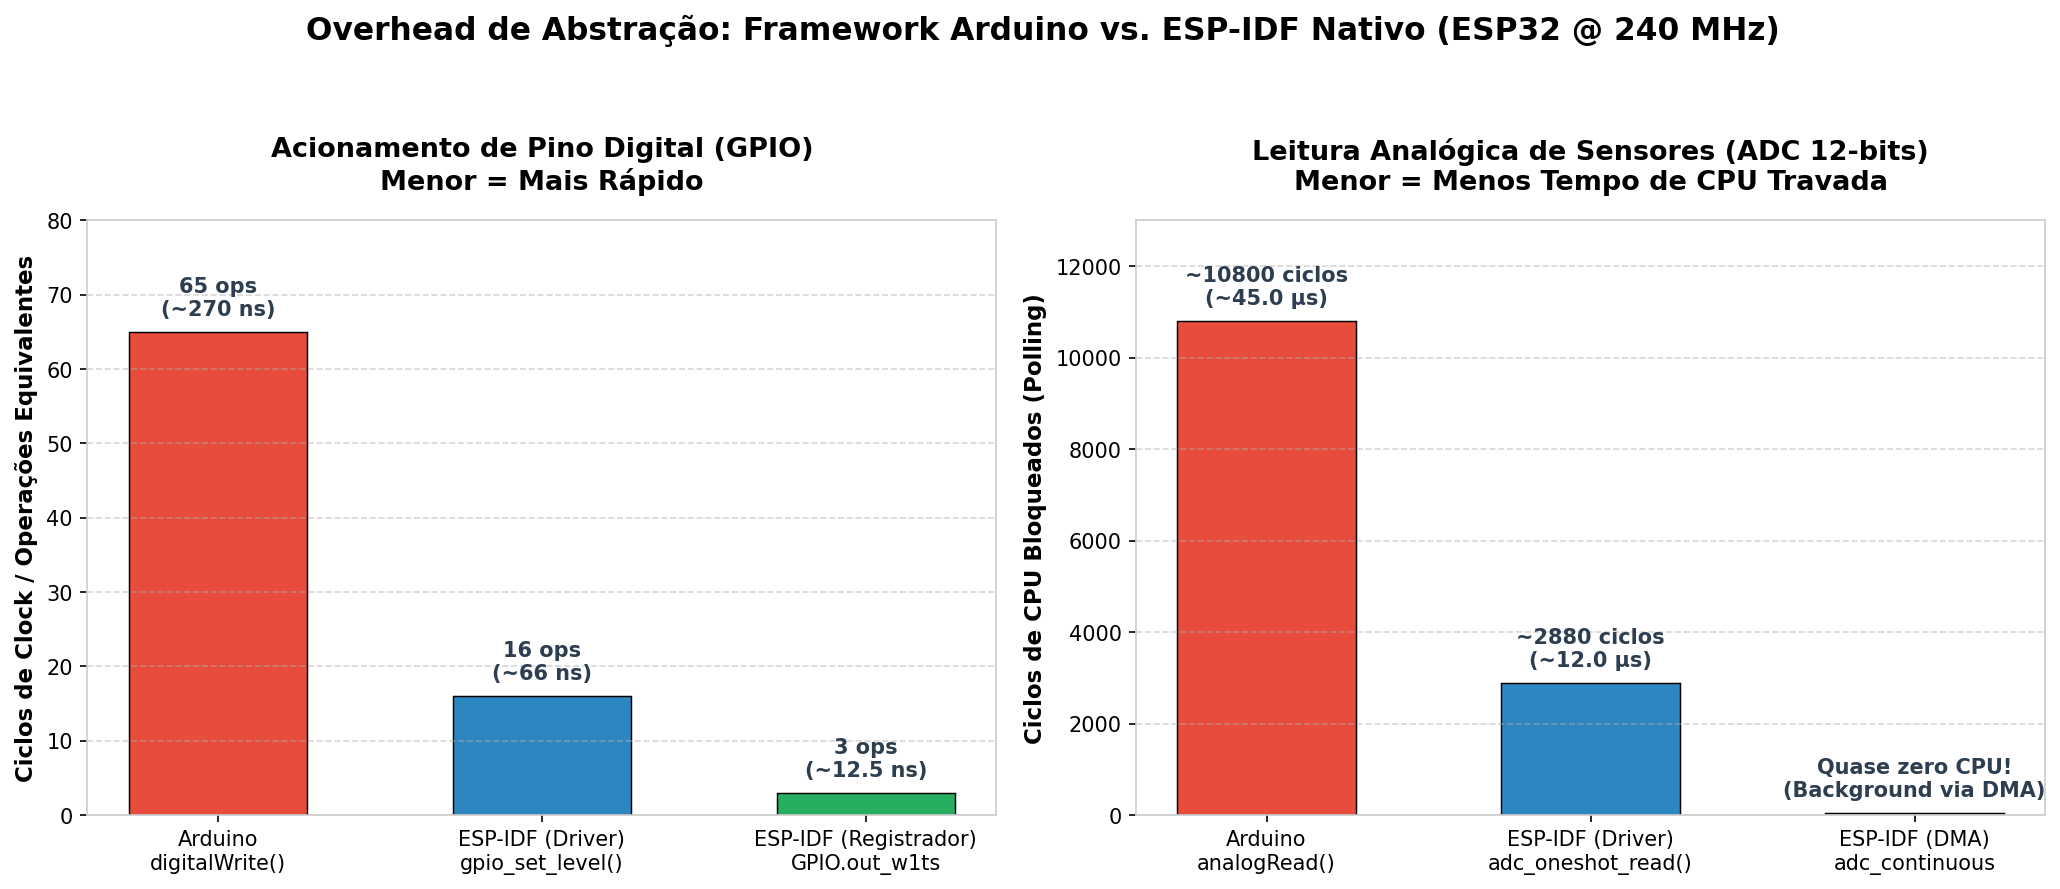

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=150)
fig.patch.set_facecolor('white')

cores_gpio = ['#E74C3C', '#2E86C1', '#27AE60']
cores_adc = ['#E74C3C', '#2E86C1', '#27AE60']

# Escrita Digital (GPIO)
categorias_gpio = [
    'Arduino\ndigitalWrite()', 
    'ESP-IDF (Driver)\ngpio_set_level()', 
    'ESP-IDF (Registrador)\nGPIO.out_w1ts'
]
ciclos_gpio = [65, 16, 3]         # Quantidade aproximada de instruções/ciclos equivalentes
tempo_ns_gpio = [270, 66, 12.5]   # Tempo aproximado a 240 MHz (em nanosegundos)

barras1 = ax1.bar(categorias_gpio, ciclos_gpio, color=cores_gpio, width=0.55, edgecolor='black', linewidth=0.7)
ax1.set_title('Acionamento de Pino Digital (GPIO)\nMenor = Mais Rápido', fontsize=13, fontweight='bold', pad=15)
ax1.set_ylabel('Ciclos de Clock / Operações Equivalentes', fontsize=11, fontweight='bold')
ax1.set_ylim(0, 80)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for barra, ciclos, tempo in zip(barras1, ciclos_gpio, tempo_ns_gpio):
    altura = barra.get_height()
    ax1.annotate(f'{ciclos} ops\n(~{tempo} ns)',
                 xy=(barra.get_x() + barra.get_width() / 2, altura),
                 xytext=(0, 6),
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold', color='#2C3E50')

#Leitura de Sensor (ADC)
categorias_adc = [
    'Arduino\nanalogRead()', 
    'ESP-IDF (Driver)\nadc_oneshot_read()', 
    'ESP-IDF (DMA)\nadc_continuous'
]
ciclos_adc = [10800, 2880, 50]    # Ciclos de CPU bloqueados esperando a conversão
tempo_us_adc = [45.0, 12.0, 0.2]  # Tempo de CPU bloqueada (em microssegundos)

barras2 = ax2.bar(categorias_adc, ciclos_adc, color=cores_adc, width=0.55, edgecolor='black', linewidth=0.7)
ax2.set_title('Leitura Analógica de Sensores (ADC 12-bits)\nMenor = Menos Tempo de CPU Travada', fontsize=13, fontweight='bold', pad=15)
ax2.set_ylabel('Ciclos de CPU Bloqueados (Polling)', fontsize=11, fontweight='bold')
ax2.set_ylim(0, 13000)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for i, (barra, ciclos, tempo) in enumerate(zip(barras2, ciclos_adc, tempo_us_adc)):
    altura = barra.get_height()
    texto_label = f'~{ciclos} ciclos\n(~{tempo} µs)' if i < 2 else 'Quase zero CPU!\n(Background via DMA)'
    ax2.annotate(texto_label,
                 xy=(barra.get_x() + barra.get_width() / 2, altura),
                 xytext=(0, 6),
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold', color='#2C3E50')

fig.suptitle('Overhead de Abstração: Framework Arduino vs. ESP-IDF Nativo (ESP32 @ 240 MHz)', 
             fontsize=15, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('comparacao_arduino_espidf.png', dpi=300)
plt.show()